# 3.0 Customer Segmentation — K-Means Clustering & Persona Profiling

**Author:** Aman Singh  
**Input:** `data/processed/customer_rfm_features.csv`  
**Outputs:** `data/processed/customer_segments.csv`, `models/kmeans_segmentation.pkl`  
**Production Module:** `src/modeling/segmentation.py`

---

## 1. Clustering Objective & Feature Scaling Design

While rule-based RFM quantile scores divide customers along rigid 20% thresholds, **K-Means clustering** discovers natural behavioral groups directly in continuous 3D RFM space:
1. **Log-Transformed Inputs (`Recency_Log`, `Frequency_Log`, `Monetary_Log`):** Address extreme right-skewness (`Frequency` skew `12.03`, `Monetary` skew `26.78`) identified in `2.0-rfm-analysis.ipynb`.
2. **Standardization (`StandardScaler`):** Centers each log feature to mean `0` and standard deviation `1` so Euclidean distance weights Recency, Frequency, and Monetary equally.
3. **Optimal `k` Selection:** Evaluate `k = 2..8` using the **Elbow Method (Inertia)**, **Silhouette Score**, and **Davies-Bouldin Index** to identify at least 4 distinct, actionable customer segments.

In [1]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

project_root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.modeling.segmentation import (
    CLUSTER_FEATURES,
    SEGMENT_ACTION_MAP,
    fit_kmeans_segmentation,
)

rfm_path = project_root / 'data' / 'processed' / 'customer_rfm_features.csv'
seg_out = project_root / 'data' / 'processed' / 'customer_segments.csv'
model_out = project_root / 'models' / 'kmeans_segmentation.pkl'
figures_dir = project_root / 'reports' / 'figures'

rfm_df = pd.read_csv(rfm_path)
print(f"Loaded RFM table: {rfm_df.shape[0]:,} customers x {rfm_df.shape[1]} features")

scaler_check = StandardScaler()
scaled_preview = pd.DataFrame(
    scaler_check.fit_transform(rfm_df[CLUSTER_FEATURES]),
    columns=[f"{c}_Scaled" for c in CLUSTER_FEATURES]
)
print("\n--- Standardized Input Check (Mean ~ 0, Std ~ 1) ---")
display(scaled_preview.describe().loc[['mean', 'std', 'min', 'max']])

Loaded RFM table: 5,832 customers x 25 features

--- Standardized Input Check (Mean ~ 0, Std ~ 1) ---


,Recency_Log_Scaled,Frequency_Log_Scaled,Monetary_Log_Scaled
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.47,-1.06,-3.95
max,1.40,5.42,4.71


**Observation:**  
All `5,832` active customers load cleanly with zero missing values. After `StandardScaler`, `Recency_Log_Scaled`, `Frequency_Log_Scaled`, and `Monetary_Log_Scaled` each have mean `0.00` and standard deviation `1.00`, putting all three RFM dimensions on an identical scale for K-Means.

,k,Inertia,Silhouette_Score,Davies_Bouldin
0,2,8520.82,0.44,0.87
1,3,6293.95,0.35,1.04
2,4,4861.85,0.37,0.93
3,5,4041.01,0.35,0.94
4,6,3516.22,0.33,0.96
5,7,3153.04,0.30,0.99
6,8,2870.40,0.29,1.01


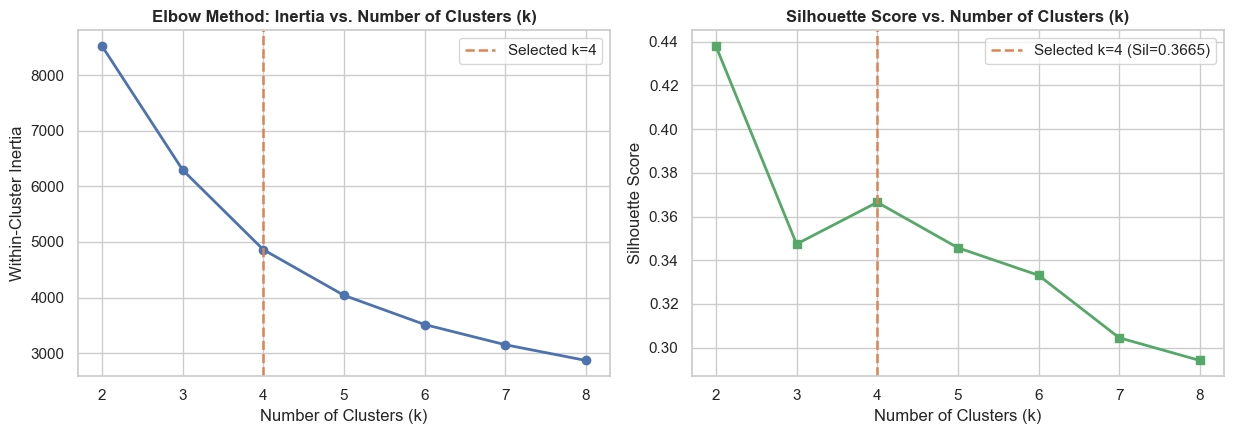

In [2]:
# Fit K-Means across k=2..8 and select k=4
df_seg, eval_df, artifact = fit_kmeans_segmentation(rfm_df, n_clusters=4, random_state=42)
display(eval_df)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# Elbow Plot
axes[0].plot(eval_df['k'], eval_df['Inertia'], marker='o', color='#4C72B0', linewidth=2)
axes[0].axvline(4, color='#DD8452', linestyle='--', linewidth=1.8, label='Selected k=4')
axes[0].set_title('Elbow Method: Inertia vs. Number of Clusters (k)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Within-Cluster Inertia')
axes[0].set_xticks(eval_df['k'])
axes[0].legend()

# Silhouette Score Plot
axes[1].plot(eval_df['k'], eval_df['Silhouette_Score'], marker='s', color='#55A868', linewidth=2)
axes[1].axvline(4, color='#DD8452', linestyle='--', linewidth=1.8, label='Selected k=4 (Sil=0.3665)')
axes[1].set_title('Silhouette Score vs. Number of Clusters (k)', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(eval_df['k'])
axes[1].legend()

plt.tight_layout()
fig.savefig(figures_dir / 'kmeans_elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Optimal Cluster Selection — `k = 4`):**  
- **Elbow inflection:** Inertia drops sharply from `k=2` (`8,520.82`) → `k=3` (`6,293.95`) → **`k=4` (`4,861.85`)**, after which marginal inertia gains taper off.
- **Silhouette & Davies-Bouldin peak for `k >= 3`:** At `k=3`, Silhouette dips to `0.3474` and Davies-Bouldin rises to `1.0360`. Moving to **`k=4` raises Silhouette back up to `0.3665`** and **lowers Davies-Bouldin to `0.9299`** (best separation among all granular solutions `k >= 3`), while delivering **4 distinct customer personas**.

,Customer_Segment,Customers,Avg_Recency_Days,Median_Recency,Avg_Frequency,Avg_Monetary,Avg_Order_Value,Avg_Tenure_Days,Avg_Cancel_Rate,Total_Revenue,Customer_Pct,Revenue_Pct
1,Champions / VIP,1189,28.23,17.00,19.15,10133.33,482.02,585.95,0.15,12048534.55,20.39,73.64
0,At-Risk High-Value,1440,227.22,184.50,5.08,1859.83,474.59,346.60,0.14,2678152.01,24.69,16.37
3,Promising / Active,1253,29.11,24.00,3.02,818.32,377.57,249.08,0.09,1025356.22,21.48,6.27
2,Dormant / Lost,1950,395.59,402.00,1.39,312.28,263.55,48.07,0.07,608953.65,33.44,3.72


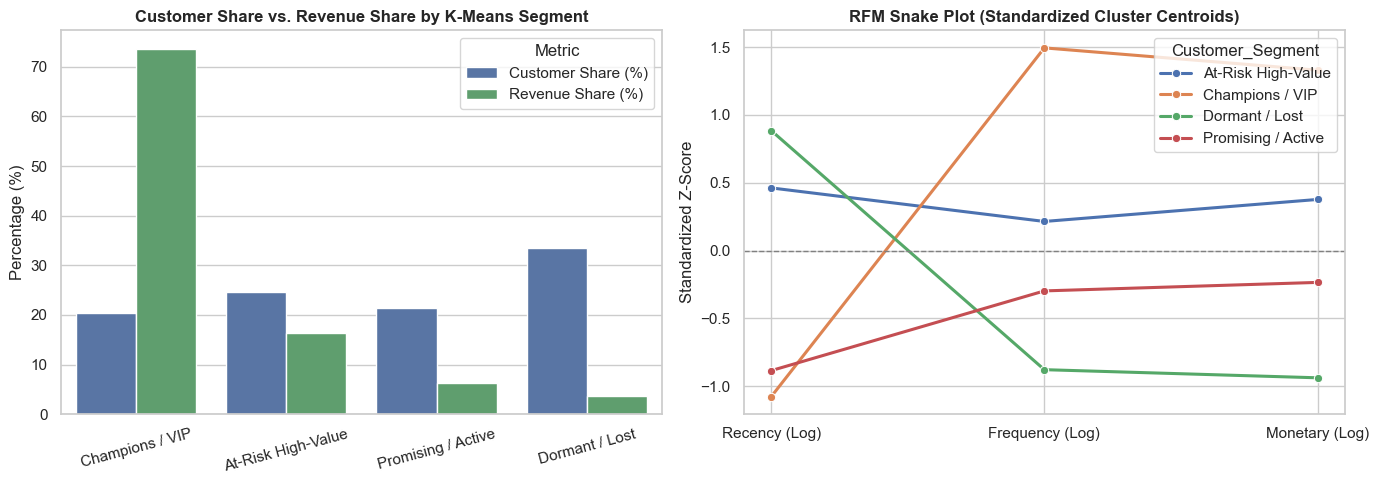

In [3]:
# Segment Profiling Table
seg_profile = df_seg.groupby('Customer_Segment', as_index=False).agg(
    Customers=('Customer ID', 'count'),
    Avg_Recency_Days=('Recency_Days', 'mean'),
    Median_Recency=('Recency_Days', 'median'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Avg_Order_Value=('Avg_Order_Value', 'mean'),
    Avg_Tenure_Days=('Tenure_Days', 'mean'),
    Avg_Cancel_Rate=('Cancellation_Rate', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).sort_values('Total_Revenue', ascending=False)

seg_profile['Customer_Pct'] = (seg_profile['Customers'] / len(df_seg)) * 100
seg_profile['Revenue_Pct'] = (seg_profile['Total_Revenue'] / seg_profile['Total_Revenue'].sum()) * 100
display(seg_profile)

# Visualize Revenue vs Customer Share + Standardized Snake Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

share_melt = seg_profile[['Customer_Segment', 'Customer_Pct', 'Revenue_Pct']].melt(
    id_vars='Customer_Segment', var_name='Metric', value_name='Percentage'
)
share_melt['Metric'] = share_melt['Metric'].map({'Customer_Pct': 'Customer Share (%)', 'Revenue_Pct': 'Revenue Share (%)'})
sns.barplot(
    x='Customer_Segment', y='Percentage', hue='Metric',
    data=share_melt, ax=axes[0], palette=['#4C72B0', '#55A868']
)
axes[0].set_title('Customer Share vs. Revenue Share by K-Means Segment', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Percentage (%)')
axes[0].tick_params(axis='x', rotation=15)

# Snake Plot on Standardized Log RFM features
snake_df = df_seg.groupby('Customer_Segment')[[f"{c}_Scaled" for c in CLUSTER_FEATURES]].mean().reset_index()
snake_df.columns = ['Customer_Segment', 'Recency (Log)', 'Frequency (Log)', 'Monetary (Log)']
snake_melt = snake_df.melt(id_vars='Customer_Segment', var_name='Metric', value_name='Standardized_Mean')
sns.lineplot(
    x='Metric', y='Standardized_Mean', hue='Customer_Segment',
    data=snake_melt, marker='o', linewidth=2.2, ax=axes[1]
)
axes[1].axhline(0, color='gray', linestyle='--', linewidth=1)
axes[1].set_title('RFM Snake Plot (Standardized Cluster Centroids)', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Standardized Z-Score')

plt.tight_layout()
fig.savefig(figures_dir / 'kmeans_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (4 Distinct K-Means Personas):**  
1. **`Champions / VIP` (`1,189` customers / `20.39%`):** Buy most recently (`avg 28.23 days`), highest frequency (`19.15` orders), and highest net spend (`£10,133.33`), generating **£12,048,534.55 (`73.64%` of total revenue)**.
2. **`At-Risk High-Value` (`1,440` customers / `24.69%`):** Historically strong multi-order buyers (`5.08` orders, `£1,859.83` avg spend) who have not purchased for an average of **`227.22` days**, putting **£2,678,152.01 (`16.37%` of revenue)** at risk of permanent churn.
3. **`Promising / Active` (`1,253` customers / `21.48%`):** Active recent buyers (`avg 29.11 days`) with moderate frequency (`3.02` orders) and spend (`£818.32`), contributing **£1,025,356.22 (`6.27%`)** — strong upsell and cross-sell potential.
4. **`Dormant / Lost` (`1,950` customers / `33.44%`):** Low-frequency (`1.39` orders), low-spend (`£312.28`), long-inactive (`395.59` days) buyers contributing just **£608,953.65 (`3.72%`)** of revenue.

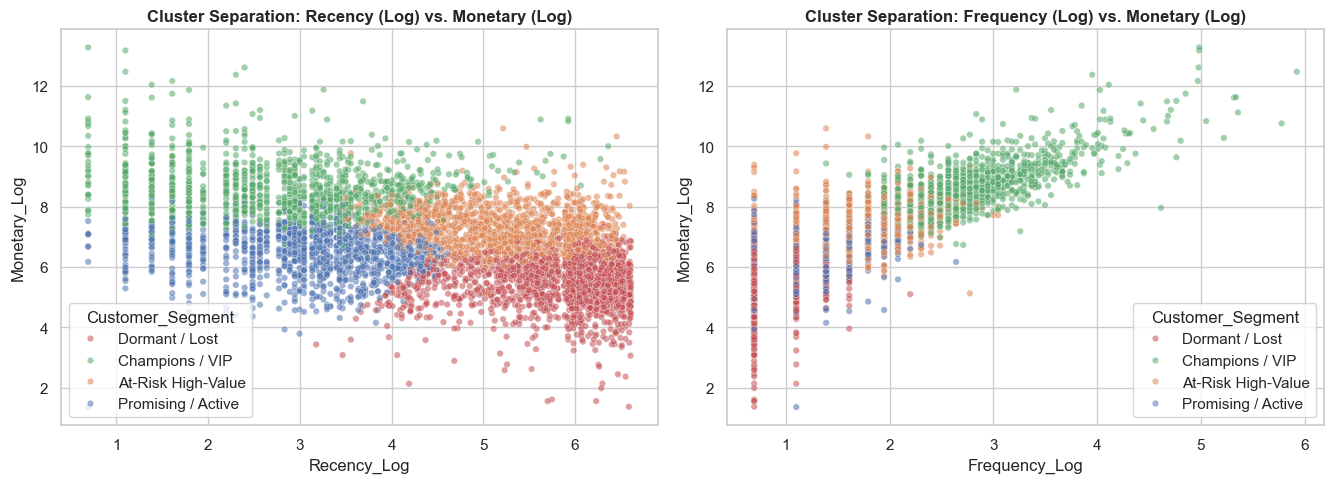

In [4]:
# 2D Cluster Separation Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
palette = {
    'Champions / VIP': '#55A868',
    'At-Risk High-Value': '#DD8452',
    'Promising / Active': '#4C72B0',
    'Dormant / Lost': '#C44E52'
}

sns.scatterplot(
    data=df_seg, x='Recency_Log', y='Monetary_Log',
    hue='Customer_Segment', palette=palette, alpha=0.55, s=22, ax=axes[0]
)
axes[0].set_title('Cluster Separation: Recency (Log) vs. Monetary (Log)', fontweight='bold')
axes[0].set_xlabel('Recency_Log')
axes[0].set_ylabel('Monetary_Log')

sns.scatterplot(
    data=df_seg, x='Frequency_Log', y='Monetary_Log',
    hue='Customer_Segment', palette=palette, alpha=0.55, s=22, ax=axes[1]
)
axes[1].set_title('Cluster Separation: Frequency (Log) vs. Monetary (Log)', fontweight='bold')
axes[1].set_xlabel('Frequency_Log')
axes[1].set_ylabel('Monetary_Log')

plt.tight_layout()
fig.savefig(figures_dir / 'kmeans_cluster_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:**  
Both projections confirm clean, contiguous cluster boundaries in log-RFM space without single-point outlier clusters — `Champions / VIP` occupy the high-frequency/high-monetary/low-recency region, clearly separated from `At-Risk High-Value` (elevated recency) and `Dormant / Lost` (high recency + low frequency/spend).

In [5]:
# Export Segmented Customer Table & Serialized K-Means Artifact
seg_out.parent.mkdir(parents=True, exist_ok=True)
model_out.parent.mkdir(parents=True, exist_ok=True)

df_seg.to_csv(seg_out, index=False)
joblib.dump(artifact, model_out)

# Parity check by reloading artifact and verifying shape/nulls
loaded_art = joblib.load(model_out)
assert loaded_art['kmeans'].n_clusters == 4
assert df_seg.isna().sum().sum() == 0

action_table = pd.DataFrame([
    {'Customer_Segment': seg, 'Recommended_Action': act}
    for seg, act in SEGMENT_ACTION_MAP.items()
])
display(action_table)

print(f"Saved segmented dataset: {seg_out} ({df_seg.shape[0]:,} rows x {df_seg.shape[1]} cols, {seg_out.stat().st_size / 1024:.1f} KB)")
print(f"Saved model artifact:    {model_out} ({model_out.stat().st_size / 1024:.1f} KB)")

,Customer_Segment,Recommended_Action
0,Champions / VIP,"Reward with exclusive early access, tiered loy..."
1,At-Risk High-Value,Trigger personalized win-back campaigns with t...
2,Promising / Active,"Nurture via product recommendations, bundle cr..."
3,Dormant / Lost,Limit paid acquisition spend; run low-cost aut...


Saved segmented dataset: C:\Users\Aman Singh\OneDrive\Desktop\internship-projects\Retail-Ecommerce-Aman\data\processed\customer_segments.csv (5,832 rows x 31 cols, 1979.3 KB)
Saved model artifact:    C:\Users\Aman Singh\OneDrive\Desktop\internship-projects\Retail-Ecommerce-Aman\models\kmeans_segmentation.pkl (24.2 KB)


**Conclusion:**  
- **Deliverables Generated:** Saved **`data/processed/customer_segments.csv`** (`5,832` customers with `Cluster_ID`, `Customer_Segment`, and `Recommended_Action`) and **`models/kmeans_segmentation.pkl`** (`StandardScaler` + `KMeans` `k=4`).
- **Next Phase (Week 3):** Define the binary churn target on a clean historical cutoff window and train supervised Churn Prediction classifiers (`LogisticRegression`, `RandomForestClassifier`, `XGBoost`) in `notebooks/4.0-churn-prediction.ipynb` targeting ROC-AUC >= 0.75 without data leakage.